## Data exploration and patient-level validation splits

Prepares a stratified five-fold cross-validation split where:

- `class_id`1-3 -> IDHmutant
- `class_id`4-6 -> IDHwildtype

The dataset contains sample entries, each with a 3D Raman array. A patient can have multiple entries, and each entry contains many spectra. The patient is therefore the split unit: and every entry and spectrum from one patient must stay in the same fold.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold

PATH = r"..\data\preprocessed.npy"
dataset = np.load(PATH, allow_pickle=True)

print(f"Sample entries: {len(dataset)}")

Sample entries: 59


### Sample-level metadata table

Each top-level dataset item is treated as one sample entry. The number of spectra is the product of the first two dimensions of `data` (for example, `(121,51,1167)` contains `121 x 51` spectra, each with 1167 channels, following the pre-processing done by Lita et al.)

In [26]:
records = pd.DataFrame([
    {
        "entry_index": i,
        "patient_id": item["patient_id"],
        "sample_name": item["name"],
        "class_id": item["class_id"],
        "n_spectra": int(np.prod(item["data"].shape[:-1])),
        "n_channels": item["data"].shape[-1],
    }
    for i, item in enumerate(dataset)
])

records.head()

,entry_index,patient_id,sample_name,class_id,n_spectra,n_channels
0,0,305,HF-305_v4b_1_1.h5_6,2,6171,1167
1,1,442,HF-442_V4BB_1.h5_12,4,2500,1167
2,2,448,HF-448_V5B_1.h5_3,1,3600,1167
3,3,592,HF-592_V3T_1.h5_4,6,3600,1167
4,4,615,HF-615_V5BB_1.h5_9,2,3600,1167


## Binary target mapping

In [27]:
target_by_class = {
    1: "IDHmutant",
    2: "IDHmutant",
    3: "IDHmutant",
    4: "IDHwildtype",
    5: "IDHwildtype",
    6: "IDHwildtype",
}

records["target"] = records["class_id"].map(target_by_class)
assert records["target"].notna().all(), "Unexpected or missing class_id found."

class_counts_per_patient = records.groupby("patient_id")["class_id"].nunique()
assert class_counts_per_patient.eq(1).all(), "At least one patient has multiple class_id values."

records.head()

,entry_index,patient_id,sample_name,class_id,n_spectra,n_channels,target
0,0,305,HF-305_v4b_1_1.h5_6,2,6171,1167,IDHmutant
1,1,442,HF-442_V4BB_1.h5_12,4,2500,1167,IDHwildtype
2,2,448,HF-448_V5B_1.h5_3,1,3600,1167,IDHmutant
3,3,592,HF-592_V3T_1.h5_4,6,3600,1167,IDHwildtype
4,4,615,HF-615_V5BB_1.h5_9,2,3600,1167,IDHmutant


## Summary at the patient level

In [28]:
patients = (
    records.groupby("patient_id", as_index=False)
    .agg(
        target=("target", "first"),
        n_samples=("entry_index", "size"),
        n_spectra=("n_spectra", "sum"),
    )
)

cohort_summary = (
    patients.groupby("target")
    .agg(
        patients=("patient_id", "nunique"),
        sample_entries=("n_samples", "sum"),
        spectra=("n_spectra", "sum"),
    )
    .reindex(["IDHmutant", "IDHwildtype"])
)

cohort_summary = cohort_summary.reset_index() # fixed misaligned table formatting
display(cohort_summary)
print(f"Unique patients: {len(patients)}")


,target,patients,sample_entries,spectra
0,IDHmutant,21,26,167414
1,IDHwildtype,25,33,133092


Unique patients: 46


In [29]:
print(cohort_summary.shape)
print(cohort_summary.index.tolist())
print(records["target"].value_counts(dropna=False))

(2, 4)
[0, 1]
target
IDHwildtype    33
IDHmutant      26
Name: count, dtype: int64


In [30]:
N_SPLITS = 5
RANDOM_STATE = 42

patients_per_class = patients["target"].value_counts()
assert patients_per_class.min() >= N_SPLITS, ( # Set minimum num of patients to at least the number of splits
    "Requires at least five patients in each target group."
)

splitter = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

patients["fold"] = -1
for fold, (_, validation_positions) in enumerate(
    splitter.split(patients["patient_id"], patients["target"])
):
    patients.loc[validation_positions, "fold"] = fold

assert patients["fold"].between(0, N_SPLITS - 1).all()
patients.sort_values(["fold", "target", "patient_id"]).reset_index(drop=True)

,patient_id,target,n_samples,n_spectra,fold
0,305,IDHmutant,1,6171,0
1,868,IDHmutant,1,7021,0
2,1016,IDHmutant,1,7497,0
3,1887,IDHmutant,1,5796,0
4,2534,IDHmutant,1,4096,0
5,1043,IDHwildtype,1,4096,0
6,2102,IDHwildtype,3,12288,0
7,2454,IDHwildtype,1,4096,0
8,2802,IDHwildtype,1,4096,0
9,2898,IDHwildtype,1,4096,0


In [31]:
fold_rows = []
for fold in range(N_SPLITS):
    patient_fold = patients[patients["fold"] == fold]
    entry_fold = records[records["patient_id"].isin(patient_fold["patient_id"])]
    fold_rows.append({
        "fold": fold + 1,
        "validation_patients": len(patient_fold),
        "IDHmutant_patients": int((patient_fold["target"] == "IDHmutant").sum()),
        "IDHwildtype_patients": int((patient_fold["target"] == "IDHwildtype").sum()),
        "validation_sample_entries": len(entry_fold),
        "validation_spectra": int(entry_fold["n_spectra"].sum()),
    })

fold_summary = pd.DataFrame(fold_rows).set_index("fold")
display(fold_summary)

,validation_patients,IDHmutant_patients,IDHwildtype_patients,validation_sample_entries,validation_spectra
fold,,,,,
1,10,5,5,12,59253
2,9,4,5,11,54925
3,9,4,5,13,67396
4,9,4,5,11,57543
5,9,4,5,12,61389


## Average spectra by IDH status

Compute spectrum-weighted channel-wise means for IDH-mutant and IDH-wildtype samples. The difference spectrum is defined as mutant minus wildtype. Since this dataset does not include a Raman-shift axis, the x-axis uses channel index.

Spectra averaged: {'IDHmutant': 167414, 'IDHwildtype': 133092}
Mean signed difference (mutant - wildtype): 0.000620387
Mean absolute difference across channels: 0.0012955


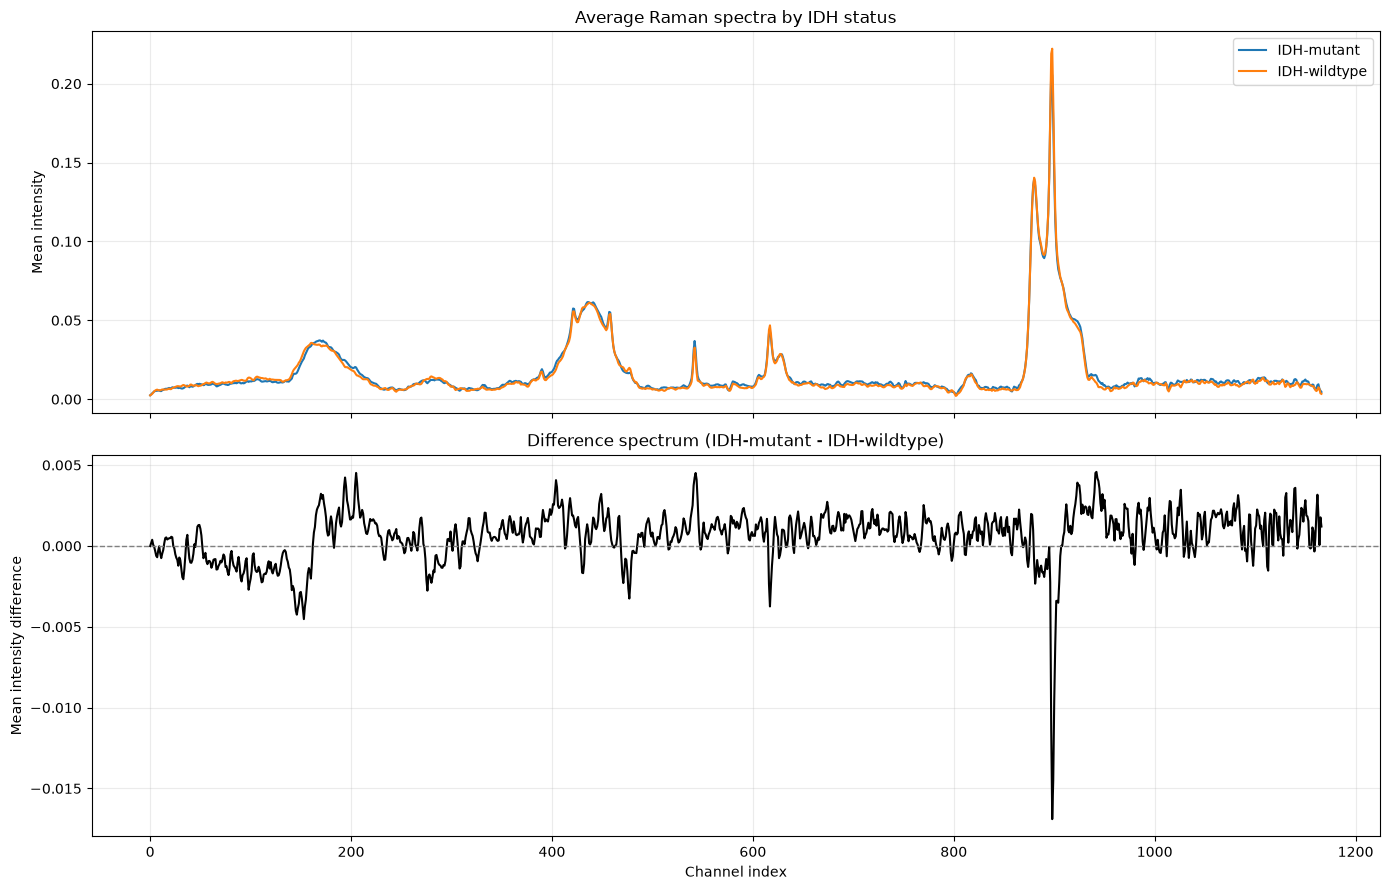

In [32]:
targets = ("IDHmutant", "IDHwildtype")
channel_count = int(records["n_channels"].iloc[0])
intensity_sums = {target: np.zeros(channel_count, dtype=np.float64) for target in targets}
spectrum_counts = {target: 0 for target in targets}

# Accumulate per-entry sums to avoid concatenating all spectra into one large array.
for entry_index, item in enumerate(dataset):
    target = records.loc[records["entry_index"] == entry_index, "target"].iloc[0]
    spectra = np.asarray(item["data"]).reshape(-1, channel_count)
    intensity_sums[target] += spectra.sum(axis=0)
    spectrum_counts[target] += spectra.shape[0]

mean_spectra = {
    target: intensity_sums[target] / spectrum_counts[target]
    for target in targets
}
difference_spectrum = mean_spectra["IDHmutant"] - mean_spectra["IDHwildtype"]
mean_signed_difference = float(difference_spectrum.mean())
mean_absolute_difference = float(np.abs(difference_spectrum).mean())

print(f"Spectra averaged: {spectrum_counts}")
print(f"Mean signed difference (mutant - wildtype): {mean_signed_difference:.6g}")
print(f"Mean absolute difference across channels: {mean_absolute_difference:.6g}")

channel_index = np.arange(channel_count)
fig, (ax_means, ax_difference) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
ax_means.plot(channel_index, mean_spectra["IDHmutant"], label="IDH-mutant")
ax_means.plot(channel_index, mean_spectra["IDHwildtype"], label="IDH-wildtype")
ax_means.set_ylabel("Mean intensity")
ax_means.set_title("Average Raman spectra by IDH status")
ax_means.legend()
ax_means.grid(alpha=0.25)

ax_difference.plot(channel_index, difference_spectrum, color="black")
ax_difference.axhline(0, color="gray", linewidth=1, linestyle="--")
ax_difference.set_xlabel("Channel index")
ax_difference.set_ylabel("Mean intensity difference")
ax_difference.set_title("Difference spectrum (IDH-mutant - IDH-wildtype)")
ax_difference.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## PCA projections by IDH status and patient

Sample the same number of spectra per patient for a balanced PCA fit, then overlay patient mean centroids. The printed eta-squared values summarize how much each PC score varies by IDH status, class ID, or patient; the within-status patient value removes the IDH group mean first. Since IDH status is constant within each patient, these are descriptive associations rather than independent causal effects. Available metadata includes patient ID, class, and sample name, but no explicit tissue-characteristic fields; PCA patterns alone cannot identify tissue or acquisition effects.

PCA sample: 201,860 spectra (5000 per patient when available)
Explained variance ratio, first 5 PCs: [0.5225 0.1058 0.0466 0.0318 0.022 ]
PC1: IDH eta-squared=0.000; class_id eta-squared=0.081; patient eta-squared=0.270; patient eta-squared within status=0.270
PC2: IDH eta-squared=0.001; class_id eta-squared=0.021; patient eta-squared=0.480; patient eta-squared within status=0.480


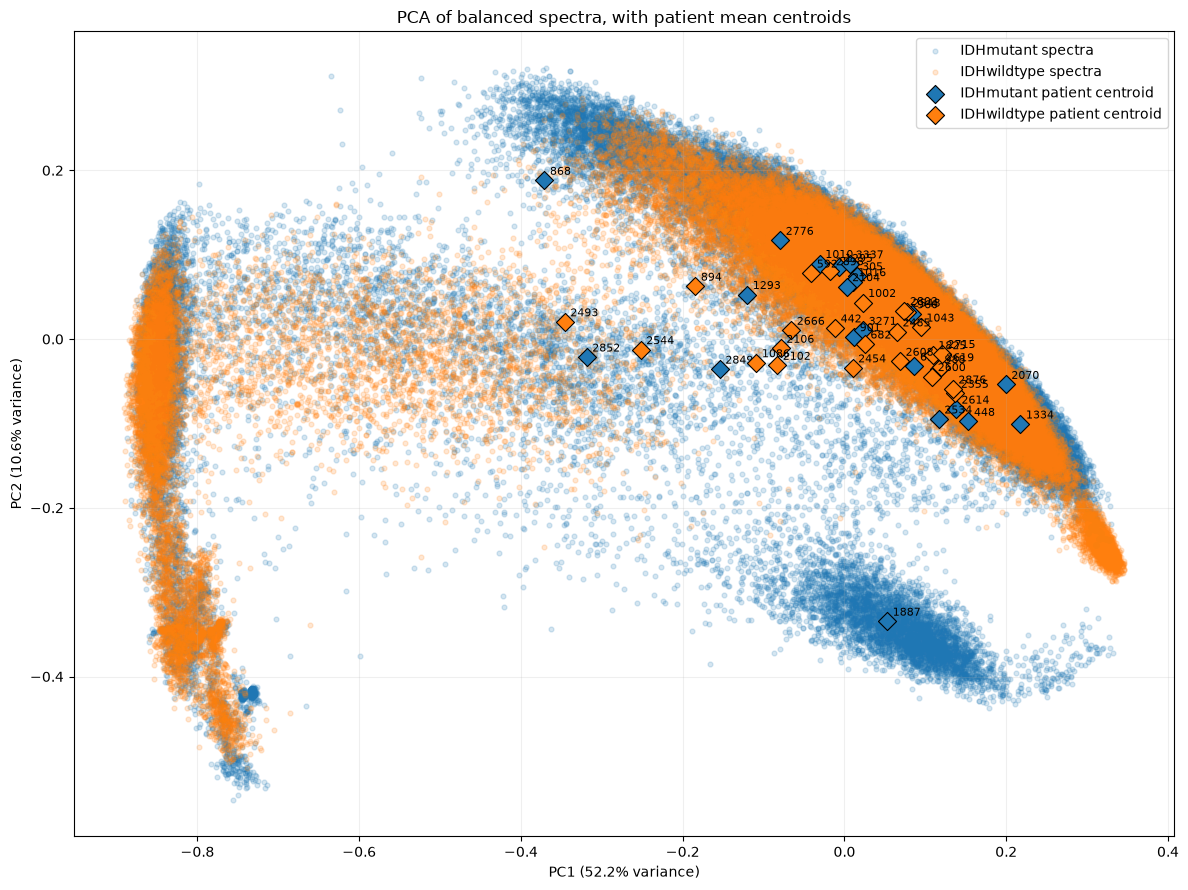

In [34]:
from sklearn.decomposition import PCA

PCA_SPECTRA_PER_PATIENT = 5000
pca_rng = np.random.default_rng(42)
channel_count = int(records['n_channels'].iloc[0])
patient_groups = records.groupby('patient_id', sort=True)
sampled_spectra, sampled_patient_ids, sampled_statuses, sampled_class_ids = [], [], [], []
patient_mean_sums, patient_spectrum_counts = {}, {}
for patient_id, entries in patient_groups:
    status = entries['target'].iloc[0]
    entry_indices = entries['entry_index'].to_numpy(dtype=int)
    patient_mean_sums[patient_id] = np.zeros(channel_count, dtype=np.float64)
    patient_spectrum_counts[patient_id] = 0
    base, extra = divmod(PCA_SPECTRA_PER_PATIENT, len(entry_indices))
    for position, entry_index in enumerate(entry_indices):
        spectra = np.asarray(dataset[entry_index]['data']).reshape(-1, channel_count)
        patient_mean_sums[patient_id] += spectra.sum(axis=0)
        patient_spectrum_counts[patient_id] += len(spectra)
        quota = base + (position < extra)
        if quota:
            chosen = pca_rng.choice(len(spectra), size=min(quota, len(spectra)), replace=False)
            sampled_spectra.append(spectra[chosen])
            sampled_patient_ids.extend([patient_id] * len(chosen))
            sampled_statuses.extend([status] * len(chosen))
            sampled_class_ids.extend([int(dataset[entry_index]['class_id'])] * len(chosen))

pca_input = np.vstack(sampled_spectra)
sampled_patient_ids = np.asarray(sampled_patient_ids)
sampled_statuses = np.asarray(sampled_statuses)
sampled_class_ids = np.asarray(sampled_class_ids)
patient_ids = np.asarray(list(patient_groups.groups.keys()))
patient_statuses = np.asarray([patient_groups.get_group(pid)['target'].iloc[0] for pid in patient_ids])
patient_means = np.vstack([patient_mean_sums[pid] / patient_spectrum_counts[pid] for pid in patient_ids])
pca = PCA(n_components=10, svd_solver='randomized', random_state=42)
sample_scores = pca.fit_transform(pca_input)
patient_centroid_scores = pca.transform(patient_means)

def eta_squared(values, labels):
    grand = values.mean()
    total = np.sum((values - grand) ** 2)
    between = sum(np.sum(labels == label) * (values[labels == label].mean() - grand) ** 2 for label in np.unique(labels))
    return between / total if total else np.nan

def patient_eta_squared_within_status(values, patient_labels, status_labels):
    residuals = values.copy()
    for status in np.unique(status_labels):
        mask = status_labels == status
        residuals[mask] -= values[mask].mean()
    total = np.sum(residuals ** 2)
    between = sum(np.sum(patient_labels == pid) * residuals[patient_labels == pid].mean() ** 2 for pid in np.unique(patient_labels))
    return between / total if total else np.nan

print(f'PCA sample: {len(pca_input):,} spectra ({PCA_SPECTRA_PER_PATIENT} per patient when available)')
print('Explained variance ratio, first 5 PCs:', np.round(pca.explained_variance_ratio_[:5], 4))
for component in range(2):
    score = sample_scores[:, component]
    print(f'PC{component + 1}: IDH eta-squared={eta_squared(score, sampled_statuses):.3f}; class_id eta-squared={eta_squared(score, sampled_class_ids):.3f}; patient eta-squared={eta_squared(score, sampled_patient_ids):.3f}; patient eta-squared within status={patient_eta_squared_within_status(score, sampled_patient_ids, sampled_statuses):.3f}')

colors = {'IDHmutant': 'tab:blue', 'IDHwildtype': 'tab:orange'}
fig, ax = plt.subplots(figsize=(12, 9))
for status, color in colors.items():
    mask = sampled_statuses == status
    ax.scatter(sample_scores[mask, 0], sample_scores[mask, 1], s=12, alpha=0.18, color=color, label=f'{status} spectra', rasterized=True)
for status, color in colors.items():
    mask = patient_statuses == status
    ax.scatter(patient_centroid_scores[mask, 0], patient_centroid_scores[mask, 1], s=85, marker='D', edgecolor='black', linewidth=0.8, color=color, label=f'{status} patient centroid', zorder=3)
    for pid, x, y in zip(patient_ids[mask], patient_centroid_scores[mask, 0], patient_centroid_scores[mask, 1]):
        ax.annotate(str(pid), (x, y), xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
ax.set_title('PCA of balanced spectra, with patient mean centroids')
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()

### Follow-up: patient 1887

Patient 1887 was noted as an outlier and excluded in a prior study using non-GP models. The next cell ranks patient centroids by Mahalanobis distance from the centroid of patients with the same IDH status in the first two PCs, and highlights patient 1887. This is a descriptive check in the displayed PCA plane.

,patient_id,target,mahalanobis_distance_pc1_pc2,rank_within_status
11,1887,IDHmutant,3.313838,1
18,2852,IDHmutant,2.583191,2
3,868,IDHmutant,2.554509,3
10,1334,IDHmutant,1.465460,4
17,2849,IDHmutant,1.423013,5
35,2493,IDHwildtype,2.812162,1
36,2544,IDHwildtype,2.295682,2
45,2898,IDHwildtype,2.138998,3
22,592,IDHwildtype,2.020150,4
24,894,IDHwildtype,1.880238,5


,patient_id,target,mahalanobis_distance_pc1_pc2,rank_within_status
11,1887,IDHmutant,3.313838,1


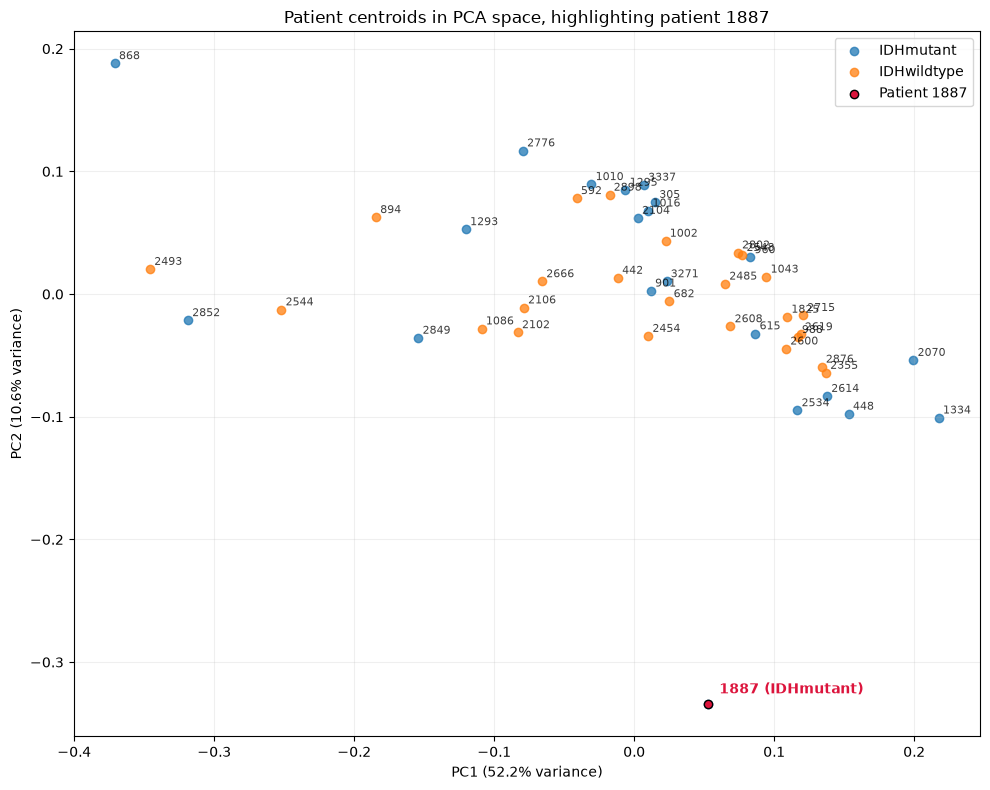

In [39]:
from numpy.linalg import pinv
centroid_scores_2d = patient_centroid_scores[:, :2]
distance_rows = []
for status in np.unique(patient_statuses):
    mask = patient_statuses == status
    group_scores = centroid_scores_2d[mask]
    centered = group_scores - group_scores.mean(axis=0)
    inverse_covariance = pinv(np.cov(group_scores, rowvar=False))
    distances = np.sqrt(np.einsum('ij,jk,ik->i', centered, inverse_covariance, centered))
    distance_rows.extend(zip(patient_ids[mask], patient_statuses[mask], distances))
patient_distance_ranking = pd.DataFrame(distance_rows, columns=['patient_id', 'target', 'mahalanobis_distance_pc1_pc2'])
patient_distance_ranking['rank_within_status'] = patient_distance_ranking.groupby('target')['mahalanobis_distance_pc1_pc2'].rank(method='min', ascending=False).astype(int)
display(patient_distance_ranking.sort_values(['target', 'rank_within_status']).groupby('target').head(5))
patient_1887 = patient_distance_ranking.loc[patient_distance_ranking['patient_id'] == 1887]
display(patient_1887)

fig, ax = plt.subplots(figsize=(10, 8))
for status, color in colors.items():
    mask = patient_statuses == status
    ax.scatter(centroid_scores_2d[mask, 0], centroid_scores_2d[mask, 1], color=color, alpha=0.75, label=status)
    for pid, x, y in zip(patient_ids[mask], centroid_scores_2d[mask, 0], centroid_scores_2d[mask, 1]):
        if pid != 1887:
            ax.annotate(str(pid), (x, y), xytext=(3, 3), textcoords='offset points', fontsize=8, alpha=0.75)
if not patient_1887.empty:
    row = int(np.flatnonzero(patient_ids == 1887)[0])
    x, y = centroid_scores_2d[row]
    ax.scatter([x], [y], color='crimson', edgecolor='black', label='Patient 1887', zorder=5)
    ax.annotate('1887 (IDHmutant)', (x, y), xytext=(8, 8), textcoords='offset points', color='crimson', fontweight='bold')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
ax.set_title('Patient centroids in PCA space, highlighting patient 1887')
ax.grid(alpha=0.2)
ax.legend()
fig.tight_layout()
plt.show()